# INDI angular-acceleration gate: delay-compensated checkpoint

**Checkpoint:** anixpkgs **9.23.11**, merged as
[anixpkgs #748](https://github.com/goromal/anixpkgs/pull/748) together with
[indi-harness #8](https://github.com/goromal/indi-harness/pull/8) (harness `e4e25cd`).
The firmware is unchanged (`8a68fdc9f0`). Vikunja tasks #167–#171.

## The problem

The measured-RPM trajectory gate checks that the INDI rate loop really inverts the plant. It does
this by comparing two signals from the firmware's `INDI` log row:

* `Px`: the **commanded** angular acceleration ν = k_w·(ω_des − ω) + ω̇_ff at tick k. The log calls
  it "predicted", but it is a command.
* `Mx`: the **measured** angular acceleration, d/dt of the gyro after the stock `INS_GYRO_FILTER`
  and the INDI estimator filter `CC3_OMG_FILT`.

Before this PR, the gate required NRMSE(`Px`, `Mx`) ≤ 0.6, and every trajectory run failed it
(raw 1.0–3.0) even though tracking was clean (0.025–0.057 m since the origin-latch fix, #163). The cause is not the controller. With an
exact inversion, the true angular acceleration follows ν through the motor dynamics, and `Mx` sees
it through two more filters. The gate was comparing a command with a response that arrives
30–50 ms later. On this plant that alone puts 0.6 out of reach for any content above about 2 Hz.

## What the PR changes, and why

| # | Change | Justification | Evidence |
|---|---|---|---|
| 1 | **Score `Mx` against the expected response, not the raw command.** `indi_harness.sitl.response_model` passes `Px` through one frame of delay → the plant's first-order motor lag (τ = 30 ms) → a 2nd-order Butterworth at the logged `INS_GYRO_FILTER` → one at the logged `CC3_OMG_FILT`. The NRMSE is computed against that. | The gate's job is to test the *inversion*. Removing the known transport delay is what makes it test that, instead of measuring physics the controller cannot change. | §2, §3 |
| 2 | **Nothing is fitted.** Filter cutoffs and loop rate are read from the log's `PARM`; τ comes from the simulator's `QuadParams`. Frame delay is fixed at 1 tick, the structural minimum, even though 2 ticks matches slightly better. | A model fitted to `Mx` could make any run pass. A fixed model from known constants cannot be tuned toward a pass. | §4 ablation |
| 3 | **The 0.6 threshold is unchanged.** So are all other gates: tracking ≤ 1.5× benign baseline, saturation ≤ 2 %, settled stock handover, live RPM feedback, G1 ceiling, linear map, X layout, altitude. | The change redefines *what* is compared, not how strict the bar is. | §6 |
| 4 | **The raw NRMSE is still reported** beside the compensated one, in the console output and in `indi_score.json` (`nrmse_raw`, `omega_dot_nrmse_raw`). | The transport delay stays visible in every report instead of being hidden. | §3, §7 |
| 5 | **Excitation floor.** A case is graded on its worst roll/pitch axis with measured RMS ≥ 0.08 rad/s², the rule `omega_gate_ok` already used. A case with no excited axis now **fails**. | On a near-still axis the NRMSE divides by noise and means nothing. Failing such a case stops a maneuver that never tested the inversion from passing. | §3 |
| 6 | **The chain restarts at logging gaps** over 5 ticks and starts each stage from steady state. | Filter state must not carry across periods when the custom controller was off. | §1 |

**Why not fix it in the controller instead?** That was tried first (Vikunja #170). Raising
`INS_GYRO_FILTER` from 20 to 60 Hz removes about 7.5 ms and improved the raw NRMSE by only about
0.09. The remaining 30 ms motor lag is plant physics (§5). The scorer change was approved
explicitly, because the #167 constraints otherwise forbid scorer changes that hide delay. Change 4
is what keeps this one honest.

**What it does not check.** The compensated gate still passes for response-gain errors up to about
±50 % (§4), so it is a coarse effectiveness check. On hardware, τ must come from bench
identification (#187).

## What this notebook verifies

It reads the SITL DataFlash logs and checks each claim directly. The response chain is
reimplemented here with `scipy.signal`, independently of the harness's `Butter2` code, and the
results are compared with the scorer's own `indi_score.json`.

| # | Claim | Check |
|---|---|---|
| 1 | `Px` and `Mx` share a row and a timestamp, logged at a steady 400 Hz | row cadence |
| 2 | The response lags the command by about 30–50 ms, and known constants account for it | delay budget, cross-correlation |
| 3 | The no-fit chain reproduces `Mx` on every run, including the weakly excited ones | NRMSE ≤ 0.6, raw vs compensated |
| 4 | Compensation does not hide a wrong inversion, and how coarse the check is | NRMSE vs gain error, stage ablation |
| 5 | Making the controller faster (`INS_GYRO_FILTER` 60 Hz) cannot close the raw gate | raw NRMSE, chain floor |
| 6 | The checkpoint passes every gate, not only the angular-acceleration one | scorer report |
| 7 | This notebook's numbers match the scorer's | max abs difference |

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from pymavlink import DFReader

DATA_ROOT = Path("/data/andrew/dev/drone/data")
# Fixed run order -> fixed colours (validated categorical slots 1-4).
RUNS = {
    "abrupt start (frame-x)": DATA_ROOT / "handover-trajectory-frame-x",
    "smooth start": DATA_ROOT / "smooth-start-trajectory-run",
    "INS_GYRO_FILTER 60": DATA_ROOT / "ins-gyro-filter-60-run",
    "checkpoint (#748)": DATA_ROOT / "compensated-gate-trajectory-run",
}
CHECKPOINT = "checkpoint (#748)"
COLORS = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
SIGNAL_COLORS = {"command": "#8a8a85", "expected": "#2a78d6", "measured": "#eb6834"}

MOTOR_TAU_S = 0.03        # indi_harness.params.QuadParams.tau_m (JSON plant)
FRAME_DELAY = 1           # ticks before a command can reach the gyro
GAP_FRAMES = 5            # restart the chain where INDI rows are this far apart
EXC_FLOOR = 0.08          # rad/s^2, omega_gate_ok excitation floor
NRMSE_TOL = 0.6
AXES = {"roll": 0, "pitch": 1}

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "grid.color": "#c3c2b7", "axes.edgecolor": "#c3c2b7",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 2.0, "legend.frameon": False})

## Load the logs

Each log is read once and keeps the `INDI` rows (command, measured accel, saturation) and the
`INDB` rows (reference and measured position), plus every `PARM`. Case windows come from the
scorer's `indi_score.json` beside each log.

In [2]:
def load_run(path):
    log = DFReader.DFReader_binary(str(path / "flight.BIN"))
    t, px, mx, sat, tb, ref, pos, fb, parameters = [], [], [], [], [], [], [], [], {}
    while (m := log.recv_match(type=["INDI", "INDB", "PARM"])) is not None:
        kind = m.get_type()
        if kind == "PARM":
            parameters[m.Name] = m.Value
        elif kind == "INDI":
            t.append(m.TimeUS); px.append([m.Px, m.Py, m.Pz]); mx.append([m.Mx, m.My, m.Mz])
            sat.append(m.S)
        else:
            tb.append(m.TimeUS); ref.append([m.RPx, m.RPy, m.RPz]); pos.append([m.Px, m.Py, m.Pz])
            fb.append(m.FB)
    score = json.loads((path / "indi_score.json").read_text())
    return {"t_us": np.asarray(t, float), "command": np.asarray(px), "measured": np.asarray(mx),
            "sat": np.asarray(sat), "indb_t_us": np.asarray(tb, float), "ref": np.asarray(ref),
            "pos": np.asarray(pos), "fallback": np.asarray(fb), "parameters": parameters,
            "score": score, "cases": [(c["case"], c["t0_us"], c["t1_us"]) for c in score["per_case"]]}


runs = {name: load_run(path) for name, path in RUNS.items()}
for name, r in runs.items():
    p = r["parameters"]
    print(f"{name:24s} INDI rows {len(r['t_us']):6d}  SCHED_LOOP_RATE {p['SCHED_LOOP_RATE']:.0f}  "
          f"INS_GYRO_FILTER {p['INS_GYRO_FILTER']:.0f}  CC3_OMG_FILT {p['CC3_OMG_FILT']:.0f}  "
          f"CC3_USE_RPM {p['CC3_USE_RPM']:.0f}  FRAME_TYPE {p['FRAME_TYPE']:.0f}")

abrupt start (frame-x)   INDI rows  21407  SCHED_LOOP_RATE 400  INS_GYRO_FILTER 20  CC3_OMG_FILT 80  CC3_USE_RPM 1  FRAME_TYPE 1
smooth start             INDI rows  23851  SCHED_LOOP_RATE 400  INS_GYRO_FILTER 20  CC3_OMG_FILT 80  CC3_USE_RPM 1  FRAME_TYPE 1
INS_GYRO_FILTER 60       INDI rows  23787  SCHED_LOOP_RATE 400  INS_GYRO_FILTER 60  CC3_OMG_FILT 80  CC3_USE_RPM 1  FRAME_TYPE 1
checkpoint (#748)        INDI rows  23890  SCHED_LOOP_RATE 400  INS_GYRO_FILTER 20  CC3_OMG_FILT 80  CC3_USE_RPM 1  FRAME_TYPE 1


## 1. Logging is not skewed

`AC_CustomControl_INDI::update()` computes `Px` and `Mx` in the same call and writes them in one
`INDI` row under a single `micros64()` stamp. So there is no logging offset to correct. What is
left to check is that rows arrive at the loop rate, with gaps only between cases (rows are written
only while the custom controller runs).

In [3]:
print(f"{'run':24s} {'median dt':>10s} {'p1':>7s} {'p99':>7s} {'gaps>3ms':>9s} {'gaps>12.5ms':>12s}")
for name, r in runs.items():
    d = np.diff(r["t_us"])
    print(f"{name:24s} {np.median(d):8.0f}us {np.percentile(d, 1):6.0f} {np.percentile(d, 99):6.0f} "
          f"{(d > 3000).sum():9d} {(d > 12500).sum():12d}")

run                       median dt      p1     p99  gaps>3ms  gaps>12.5ms
abrupt start (frame-x)       2499us   2499   2499        26            0
smooth start                 2499us   2499   2499        28            0
INS_GYRO_FILTER 60           2499us   2499   2499        28            0
checkpoint (#748)            2499us   2499   2499        28            0


The rows are a steady 2499 µs apart (400 Hz). No gap reaches 12.5 ms: the custom controller stays
engaged across both cases (between cases only the outer loop falls back), so the response chain
runs continuously. The 26–28 gaps over 3 ms are single missed ticks.

## 2. The delay budget

The chain from command to logged measurement is

ν → one-frame delay → first-order motor lag (τ = 30 ms) → `INS_GYRO_FILTER` (2nd-order
Butterworth) → `CC3_OMG_FILT` (2nd-order Butterworth) → `Mx`.

At low frequency, a first-order lag delays by τ, and a 2nd-order Butterworth delays by
√2 / (2π f_c).

In [4]:
def butter_delay_ms(fc):
    return 1e3 * np.sqrt(2) / (2 * np.pi * fc) if fc else 0.0


for label, ins in (("INS_GYRO_FILTER 20", 20.0), ("INS_GYRO_FILTER 60", 60.0)):
    stages = {"frame delay": 2.5, "motor lag": MOTOR_TAU_S * 1e3,
              "gyro filter": butter_delay_ms(ins), "estimator 80 Hz": butter_delay_ms(80.0)}
    total = sum(stages.values())
    print(f"{label}: " + ", ".join(f"{k} {v:.1f} ms" for k, v in stages.items()) + f"  -> {total:.1f} ms")

INS_GYRO_FILTER 20: frame delay 2.5 ms, motor lag 30.0 ms, gyro filter 11.3 ms, estimator 80 Hz 2.8 ms  -> 46.6 ms
INS_GYRO_FILTER 60: frame delay 2.5 ms, motor lag 30.0 ms, gyro filter 3.8 ms, estimator 80 Hz 2.8 ms  -> 39.1 ms


The chain below follows the firmware. Each stage starts from steady state at the first sample, and
the chain restarts at logging gaps. It never looks at `Mx`.

In [5]:
def chain_segment(nu, fs, tau, ins_hz, est_hz, frame_delay=FRAME_DELAY):
    y = np.asarray(nu, float)
    if frame_delay:
        y = np.concatenate([np.repeat(y[:1], frame_delay, axis=0), y[:-frame_delay]])
    if tau:
        k = (1.0 / fs) / tau
        b, a = [k], [1.0, -(1.0 - k)]
        y = signal.lfilter(b, a, y, axis=0, zi=np.outer(signal.lfilter_zi(b, a), y[0]))[0]
    for fc in (ins_hz, est_hz):
        if fc:
            b, a = signal.butter(2, fc / (fs / 2))
            y = signal.lfilter(b, a, y, axis=0, zi=np.outer(signal.lfilter_zi(b, a), y[0]))[0]
    return y


def expected_response(r, tau=MOTOR_TAU_S, ins_hz="log", est_hz="log", gain=1.0, frame_delay=FRAME_DELAY):
    p = r["parameters"]
    fs = p["SCHED_LOOP_RATE"]
    ins_hz = (p["INS_GYRO_FILTER"] or None) if ins_hz == "log" else ins_hz
    est_hz = (p["CC3_OMG_FILT"] or None) if est_hz == "log" else est_hz
    breaks = np.flatnonzero(np.diff(r["t_us"]) > GAP_FRAMES * 1e6 / fs) + 1
    bounds = np.r_[0, breaks, len(r["t_us"])]
    return gain * np.concatenate([chain_segment(r["command"][a:b], fs, tau, ins_hz, est_hz, frame_delay)
                                  for a, b in zip(bounds[:-1], bounds[1:])])


for r in runs.values():
    r["expected"] = expected_response(r)

**Delay seen in the data.** For each case and axis, the shift of `Px` that best matches `Mx` (raw),
compared with the delay the chain itself implies (the shift of `Px` that best matches the chain
output). The excitation column shows how strongly the case actually moved that axis.

In [6]:
def window(r, t0, t1):
    return (r["t_us"] >= t0) & (r["t_us"] <= t1)


def nrmse(pred, meas):
    return float(np.sqrt(np.mean((pred - meas) ** 2)) / np.sqrt(np.mean(meas ** 2)))


def best_shift_ms(a, b, max_ticks=40):
    errs = [nrmse(a[: len(a) - L] if L else a, b[L:]) for L in range(max_ticks + 1)]
    return 2.5 * int(np.argmin(errs)), float(min(errs))


print(f"{'run':24s} {'case':16s} {'axis':5s} {'exc':>6s} {'Mx vs Px':>9s} {'chain':>7s}")
for name, r in runs.items():
    for case, t0, t1 in r["cases"]:
        w = window(r, t0, t1)
        for axis, i in AXES.items():
            cmd, meas = r["command"][w, i], r["measured"][w, i]
            shift, _ = best_shift_ms(cmd, meas)
            chain_shift, _ = best_shift_ms(cmd, r["expected"][w, i])
            exc = np.sqrt(np.mean(meas ** 2))
            print(f"{name:24s} {case:16s} {axis:5s} {exc:6.2f} {shift:7.1f}ms {chain_shift:5.1f}ms")

run                      case             axis     exc  Mx vs Px   chain
abrupt start (frame-x)   circle_slow      roll    2.70    47.5ms  40.0ms
abrupt start (frame-x)   circle_slow      pitch   0.40    40.0ms  32.5ms
abrupt start (frame-x)   lemniscate_fast  roll    4.70    50.0ms  40.0ms
abrupt start (frame-x)   lemniscate_fast  pitch   3.08    55.0ms  40.0ms
smooth start             circle_slow      roll    0.18    37.5ms  30.0ms
smooth start             circle_slow      pitch   0.17    35.0ms  30.0ms
smooth start             lemniscate_fast  roll    1.91    47.5ms  40.0ms
smooth start             lemniscate_fast  pitch   0.45    37.5ms  32.5ms
INS_GYRO_FILTER 60       circle_slow      roll    0.14    17.5ms  15.0ms
INS_GYRO_FILTER 60       circle_slow      pitch   0.14    17.5ms  15.0ms
INS_GYRO_FILTER 60       lemniscate_fast  roll    1.65    40.0ms  32.5ms
INS_GYRO_FILTER 60       lemniscate_fast  pitch   0.48    32.5ms  15.0ms
checkpoint (#748)        circle_slow      roll    0

**Why the raw gate cannot pass.** For a sinusoid at frequency f, a perfectly inverted loop still
leaves a raw error of |1 − H(j2πf)| relative to the response, where H is the chain's frequency
response. Above the frequency where that curve crosses 0.6, the raw gate fails whatever the
controller does.

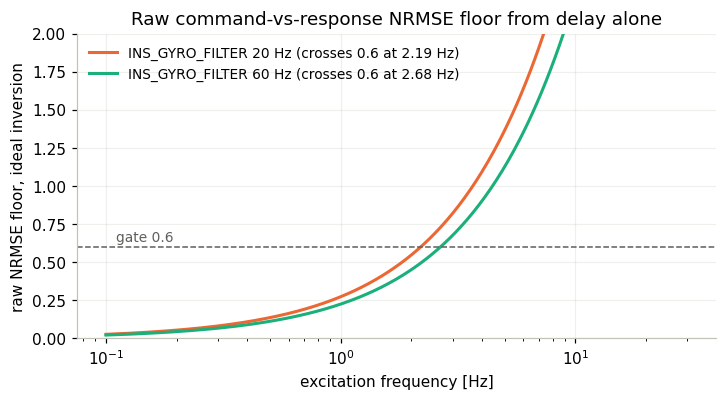

In [7]:
fs = 400.0
f = np.logspace(-1, np.log10(30), 400)
z = np.exp(1j * 2 * np.pi * f / fs)
k = (1 / fs) / MOTOR_TAU_S
motor = k / (1 - (1 - k) / z)


def butter_response(fc):
    b, a = signal.butter(2, fc / (fs / 2))
    return np.polyval(b[::-1], 1 / z) / np.polyval(a[::-1], 1 / z)


fig, ax = plt.subplots(figsize=(7.5, 3.6))
for label, ins, color in (("INS_GYRO_FILTER 20 Hz", 20.0, COLORS["smooth start"]),
                          ("INS_GYRO_FILTER 60 Hz", 60.0, COLORS["INS_GYRO_FILTER 60"])):
    H = (1 / z) * motor * butter_response(ins) * butter_response(80.0)
    floor = np.abs(1 - H) / np.abs(H)      # normalized by the response RMS, as the gate is
    crossing = f[np.argmax(floor > NRMSE_TOL)]
    ax.semilogx(f, floor, color=color, label=f"{label} (crosses 0.6 at {crossing:.2f} Hz)")
ax.axhline(NRMSE_TOL, color="#5f5e5a", lw=1, ls="--")
ax.text(0.11, NRMSE_TOL + 0.04, "gate 0.6", color="#5f5e5a", fontsize=9)
ax.set(xlabel="excitation frequency [Hz]", ylabel="raw NRMSE floor, ideal inversion",
       ylim=(0, 2), title="Raw command-vs-response NRMSE floor from delay alone")
ax.legend(loc="upper left", fontsize=9)
plt.show()

## 3. The chain reproduces the measurement

A short stretch of `lemniscate_fast` roll from the checkpoint. The command (gray) leads, the
measured accel (orange) trails, and the chain output (blue) lies on the measurement.

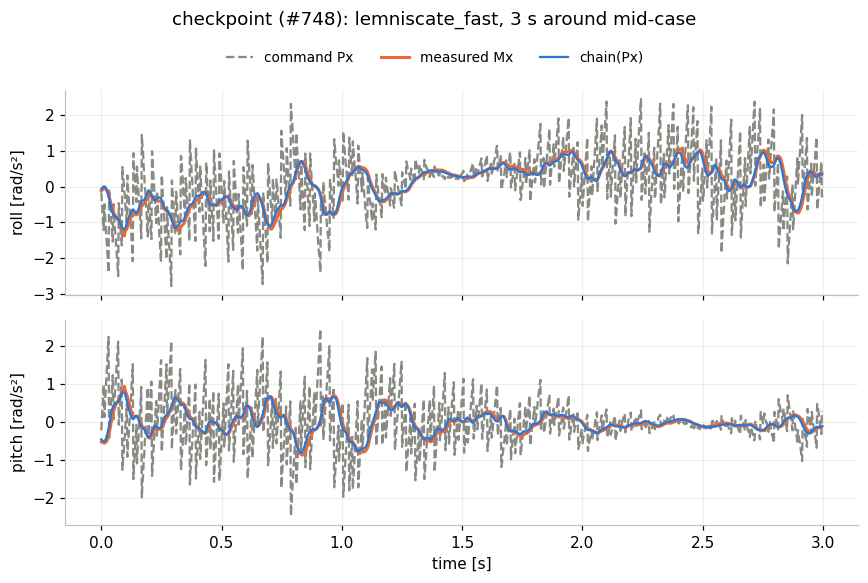

In [8]:
r = runs[CHECKPOINT]
case, t0, t1 = [c for c in r["cases"] if c[0] == "lemniscate_fast"][0]
mid = 0.5 * (t0 + t1)
w = (r["t_us"] >= mid - 1.5e6) & (r["t_us"] <= mid + 1.5e6)
ts = (r["t_us"][w] - r["t_us"][w][0]) / 1e6
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for ax, (axis, i) in zip(axes, AXES.items()):
    ax.plot(ts, r["command"][w, i], color=SIGNAL_COLORS["command"], lw=1.5, ls="--", label="command Px")
    ax.plot(ts, r["measured"][w, i], color=SIGNAL_COLORS["measured"], label="measured Mx")
    ax.plot(ts, r["expected"][w, i], color=SIGNAL_COLORS["expected"], lw=1.5, label="chain(Px)")
    ax.set_ylabel(f"{axis} [rad/s²]")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper center", ncol=3, fontsize=9,
           bbox_to_anchor=(0.5, 1.0))
fig.suptitle(f"{CHECKPOINT}: {case}, 3 s around mid-case", y=1.05)
axes[-1].set_xlabel("time [s]")
plt.tight_layout(); plt.show()

**Every run, case and axis.** Raw is the old gate's comparison, compensated is the new one, and
excitation is the RMS of the measured accel. Axes below the 0.08 rad/s² floor would not count
toward the gate; none fall below it here.

In [9]:
rows = []
for name, r in runs.items():
    for case, t0, t1 in r["cases"]:
        w = window(r, t0, t1)
        for axis, i in AXES.items():
            meas = r["measured"][w, i]
            rows.append({"run": name, "case": case, "axis": axis,
                         "exc": float(np.sqrt(np.mean(meas ** 2))),
                         "raw": nrmse(r["command"][w, i], meas),
                         "compensated": nrmse(r["expected"][w, i], meas)})

print(f"{'run':24s} {'case':16s} {'axis':5s} {'exc':>6s} {'raw':>7s} {'comp':>7s}")
for row in rows:
    print(f"{row['run']:24s} {row['case']:16s} {row['axis']:5s} {row['exc']:6.2f} "
          f"{row['raw']:7.3f} {row['compensated']:7.3f}")
print(f"\nworst compensated: {max(r['compensated'] for r in rows):.3f}   "
      f"best raw: {min(r['raw'] for r in rows):.3f}   gate {NRMSE_TOL}")

run                      case             axis     exc     raw    comp
abrupt start (frame-x)   circle_slow      roll    2.70   1.043   0.131
abrupt start (frame-x)   circle_slow      pitch   0.40   1.456   0.164
abrupt start (frame-x)   lemniscate_fast  roll    4.70   1.019   0.239
abrupt start (frame-x)   lemniscate_fast  pitch   3.08   1.133   0.390
smooth start             circle_slow      roll    0.18   2.302   0.262
smooth start             circle_slow      pitch   0.17   2.544   0.292
smooth start             lemniscate_fast  roll    1.91   1.041   0.130
smooth start             lemniscate_fast  pitch   0.45   1.530   0.242
INS_GYRO_FILTER 60       circle_slow      roll    0.14   2.790   0.331
INS_GYRO_FILTER 60       circle_slow      pitch   0.14   2.988   0.356
INS_GYRO_FILTER 60       lemniscate_fast  roll    1.65   0.950   0.176
INS_GYRO_FILTER 60       lemniscate_fast  pitch   0.48   1.438   0.226
checkpoint (#748)        circle_slow      roll    0.18   2.367   0.278
checkp

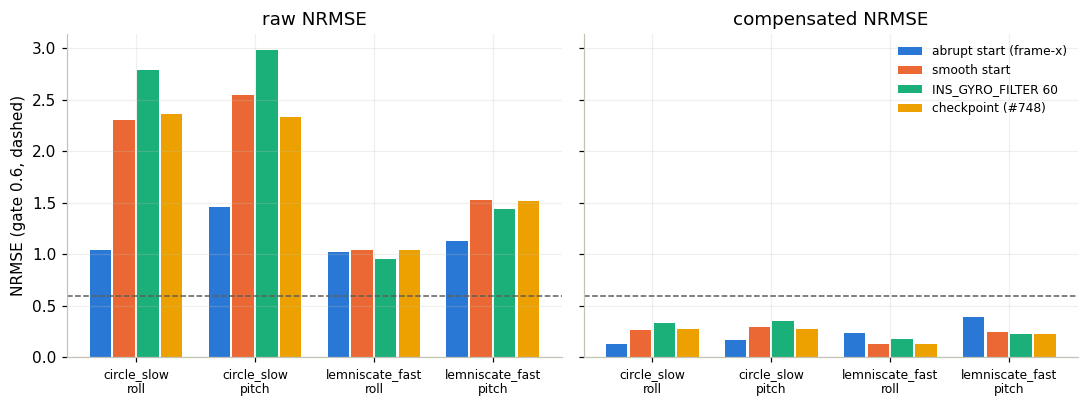

In [10]:
labels = sorted({(row["case"], row["axis"]) for row in rows}, key=lambda c: (c[0], c[1] != "roll"))
x = np.arange(len(labels))
width = 0.8 / len(runs)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, metric in zip(axes, ("raw", "compensated")):
    for j, name in enumerate(runs):
        vals = [next(r[metric] for r in rows if r["run"] == name and (r["case"], r["axis"]) == lab)
                for lab in labels]
        ax.bar(x + (j - (len(runs) - 1) / 2) * width, vals, width * 0.9, color=COLORS[name], label=name)
    ax.axhline(NRMSE_TOL, color="#5f5e5a", lw=1, ls="--")
    ax.set_xticks(x, [f"{c}\n{a}" for c, a in labels], fontsize=8)
    ax.set_title(f"{metric} NRMSE")
axes[0].set_ylabel("NRMSE (gate 0.6, dashed)")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 4. Compensation does not hide a wrong inversion

**Gain error.** If the inversion used the wrong effectiveness G1, the response would be scaled
by roughly G1_true/G1. Scaling the chain output by a factor g shows how far the gate tolerates a
gain error. A minimum near g = 1 means the actual response size matches the command, which is the
property the gate is meant to check. The width of the region below 0.6 is how coarse a check the
gate is.

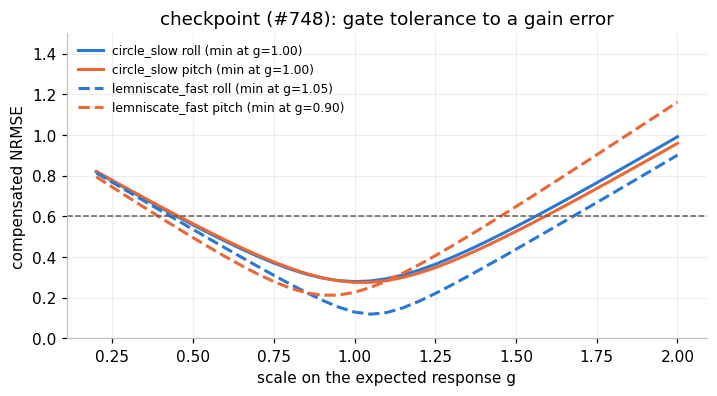

In [11]:
gains = np.linspace(0.2, 2.0, 37)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
r = runs[CHECKPOINT]
for (case, t0, t1), ls in zip(r["cases"], ("-", "--")):
    w = window(r, t0, t1)
    for axis, i in AXES.items():
        curve = [nrmse(g * r["expected"][w, i], r["measured"][w, i]) for g in gains]
        color = SIGNAL_COLORS["expected"] if axis == "roll" else SIGNAL_COLORS["measured"]
        ax.plot(gains, curve, color=color, ls=ls, label=f"{case} {axis} (min at g={gains[np.argmin(curve)]:.2f})")
ax.axhline(NRMSE_TOL, color="#5f5e5a", lw=1, ls="--")
ax.set(xlabel="scale on the expected response g", ylabel="compensated NRMSE", ylim=(0, 1.5),
       title=f"{CHECKPOINT}: gate tolerance to a gain error")
ax.legend(fontsize=8)
plt.show()

**Stage ablation.** Each chain stage is removed in turn. If a stage were unnecessary, removing it
would not hurt the match. Every stage hurts it, the motor lag most.

In [12]:
variants = {
    "full chain": {},
    "no motor lag": {"tau": None},
    "no gyro filter": {"ins_hz": None},
    "no estimator filter": {"est_hz": None},
    "no frame delay": {"frame_delay": 0},
    "two-frame delay": {"frame_delay": 2},
}
print(f"{'run':24s} {'case':16s} " + " ".join(f"{v:>19s}" for v in variants))
for name, r in runs.items():
    outs = {v: expected_response(r, **kw) for v, kw in variants.items()}
    for case, t0, t1 in r["cases"]:
        w = window(r, t0, t1)
        worst = {v: max(nrmse(o[w, i], r["measured"][w, i]) for i in AXES.values()) for v, o in outs.items()}
        print(f"{name:24s} {case:16s} " + " ".join(f"{worst[v]:19.3f}" for v in variants))

run                      case                      full chain        no motor lag      no gyro filter no estimator filter      no frame delay     two-frame delay
abrupt start (frame-x)   circle_slow                    0.164               0.800               0.423               0.211               0.212               0.125
abrupt start (frame-x)   lemniscate_fast                0.390               0.795               0.547               0.417               0.418               0.367
smooth start             circle_slow                    0.292               1.228               0.667               0.351               0.352               0.249
smooth start             lemniscate_fast                0.242               0.847               0.454               0.274               0.274               0.220
INS_GYRO_FILTER 60       circle_slow                    0.356               2.165               0.507               0.450               0.446               0.311
INS_GYRO_FILTER 60       lem

The two-frame delay matches slightly better than one frame. The gate keeps one frame, the minimum
the loop structure forces, so the model is not tuned toward a pass.

## 5. A faster gyro filter barely moves the raw gate

`INS_GYRO_FILTER` 60 Hz takes about 7.5 ms out of the chain. Here is what it does to the raw gate
on the case with real excitation:

In [13]:
for name in ("smooth start", "INS_GYRO_FILTER 60"):
    sel = [row for row in rows if row["run"] == name and row["case"] == "lemniscate_fast"]
    print(f"{name:20s} lemniscate_fast raw roll/pitch: " +
          " / ".join(f"{row['raw']:.3f}" for row in sel) +
          "   compensated: " + " / ".join(f"{row['compensated']:.3f}" for row in sel))

smooth start         lemniscate_fast raw roll/pitch: 1.041 / 1.530   compensated: 0.130 / 0.242
INS_GYRO_FILTER 60   lemniscate_fast raw roll/pitch: 0.950 / 1.438   compensated: 0.176 / 0.226


The improvement is about 0.09. The 30 ms motor lag is plant physics that the controller cannot
remove. The faster filter only moves the raw floor's 0.6 crossing from about 2.2 Hz to 2.7 Hz
(section 2).

## 6. The checkpoint passes every gate

These values come straight from the scorer's report, `indi_score.json`, for the checkpoint VM run.

In [14]:
s = runs[CHECKPOINT]["score"]
checks = []
for c in s["buzz_closes"]["per_case"]:
    checks += [
        (f"{c['case']}: tracking RMS", f"{c['track_rms']:.3f} m", f"<= {c['benign_rms'] * s['buzz_closes']['tol']:.3f} m", c["track_ok"]),
        (f"{c['case']}: saturation", f"{c['sat_frac']:.3f}", f"<= {s['buzz_closes']['sat_tol']}", c["sat_ok"]),
        (f"{c['case']}: omega_dot NRMSE (raw {c['omega_dot_nrmse_raw']:.2f})", f"{c['omega_dot_nrmse']:.3f}", f"<= {s['buzz_closes']['nrmse_tol']}", c["nrmse_ok"]),
        (f"{c['case']}: roll/pitch excited", str(c["omega_excited"]), "True", c["omega_excited"]),
    ]
h = s["stock_handover"]
checks += [
    ("stock handover peak rate", f"{h['peak_roll_pitch_rate_rad_s']:.4f} rad/s", f"< {h['limit_rad_s']}", h["peak_roll_pitch_rate_rad_s"] < h["limit_rad_s"]),
    ("custom controller engaged", str(s["engagement"]["indi_active"]), "True", s["engagement"]["indi_active"]),
    ("RPM fallback fraction", f"{s['indc_health']['fallback_frac']:.3f}", "< 0.5", s["indc_health"]["fallback_frac"] < 0.5),
    ("peak altitude", f"{s['peak_alt_m']:.1f} m", "< 14 m", s["peak_alt_m"] < 14),
    ("G1 ratio to analytic", f"{max(s['g1_ceiling']['ratios']):.2f}", "< 3", max(s["g1_ceiling"]["ratios"]) < 3),
    ("linear actuator map", str(s["g1_ceiling"]["linear_map"]), "True", s["g1_ceiling"]["linear_map"]),
    ("X actuator layout", str(s["actuator_layout"]["ok"]), "True", s["actuator_layout"]["ok"]),
]
for label, value, limit, ok in checks:
    print(f"{'PASS' if ok else 'FAIL':4s}  {label:52s} {value:>14s}  {limit}")
print("\nresponse chain:", s["response_chain"])
print("OVERALL:", "PASS" if all(ok for *_, ok in checks) else "FAIL")

PASS  circle_slow: tracking RMS                                   0.025 m  <= 0.727 m
PASS  circle_slow: saturation                                       0.000  <= 0.02
PASS  circle_slow: omega_dot NRMSE (raw 2.37)                       0.278  <= 0.6
PASS  circle_slow: roll/pitch excited                                True  True
PASS  lemniscate_fast: tracking RMS                               0.053 m  <= 1.067 m
PASS  lemniscate_fast: saturation                                   0.000  <= 0.02
PASS  lemniscate_fast: omega_dot NRMSE (raw 1.52)                   0.226  <= 0.6
PASS  lemniscate_fast: roll/pitch excited                            True  True
PASS  stock handover peak rate                               0.0039 rad/s  < 1.0
PASS  custom controller engaged                                      True  True
PASS  RPM fallback fraction                                         0.000  < 0.5
PASS  peak altitude                                                10.0 m  < 14 m
PASS  G1 ratio

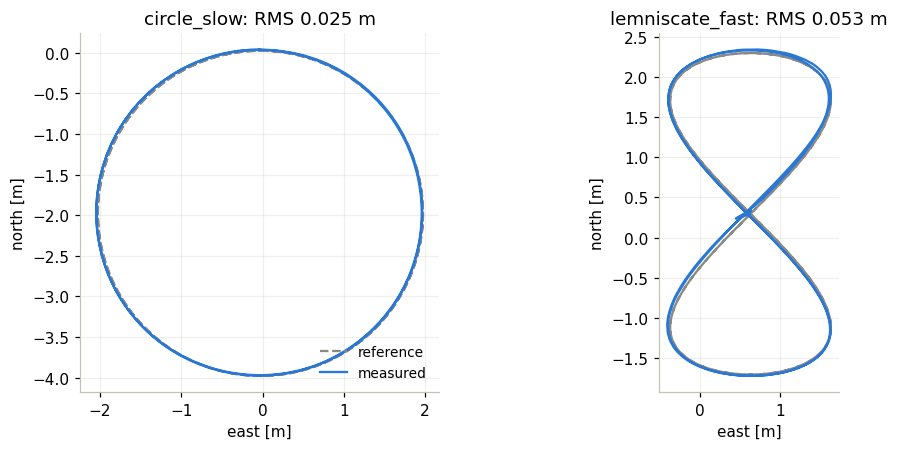

In [15]:
r = runs[CHECKPOINT]
active = r["fallback"] == 0
breaks = np.flatnonzero(np.diff(np.r_[0, active.astype(int), 0]))
blocks = [(a, b) for a, b in zip(breaks[::2], breaks[1::2]) if b - a > 400]
fig, axes = plt.subplots(1, len(blocks), figsize=(10, 4.2))
for ax, (a, b), (case, *_) in zip(np.atleast_1d(axes), blocks, r["cases"]):
    ax.plot(r["ref"][a:b, 1], r["ref"][a:b, 0], color=SIGNAL_COLORS["command"], lw=1.5, ls="--", label="reference")
    ax.plot(r["pos"][a:b, 1], r["pos"][a:b, 0], color=SIGNAL_COLORS["expected"], lw=1.5, label="measured")
    err = np.linalg.norm(r["ref"][a:b] - r["pos"][a:b], axis=1)
    ax.set(title=f"{case}: RMS {np.sqrt(np.mean(err ** 2)):.3f} m", xlabel="east [m]", ylabel="north [m]", aspect="equal")
np.atleast_1d(axes)[0].legend(fontsize=9, loc="lower right")
plt.tight_layout(); plt.show()

## 7. Cross-check against the scorer

The scorer uses the harness's own `Butter2` filter; this notebook uses `scipy.signal`. Both should
give the same compensated and raw NRMSE for every case and axis of the checkpoint.

In [16]:
r = runs[CHECKPOINT]
worst = 0.0
for c in r["score"]["per_case"]:
    w = window(r, c["t0_us"], c["t1_us"])
    for axis, i in AXES.items():
        ours = nrmse(r["expected"][w, i], r["measured"][w, i])
        ours_raw = nrmse(r["command"][w, i], r["measured"][w, i])
        theirs = c["omega_compensated"][axis]
        diff = max(abs(ours - theirs["nrmse"]), abs(ours_raw - theirs["nrmse_raw"]))
        worst = max(worst, diff)
        print(f"{c['case']:16s} {axis:5s} notebook {ours:.4f} / raw {ours_raw:.4f}   "
              f"scorer {theirs['nrmse']:.4f} / raw {theirs['nrmse_raw']:.4f}")
print(f"max abs difference: {worst:.2e}  ->", "MATCH" if worst < 1e-3 else "MISMATCH")

circle_slow      roll  notebook 0.2784 / raw 2.3670   scorer 0.2784 / raw 2.3670
circle_slow      pitch notebook 0.2746 / raw 2.3330   scorer 0.2746 / raw 2.3330
lemniscate_fast  roll  notebook 0.1284 / raw 1.0462   scorer 0.1284 / raw 1.0462
lemniscate_fast  pitch notebook 0.2257 / raw 1.5173   scorer 0.2257 / raw 1.5173
max abs difference: 5.83e-16  -> MATCH


## Conclusions

1. **No timestamp skew.** `Px` and `Mx` share one row and one stamp at a steady 400 Hz. The gap
   between them is causal: a command, then its response.
2. **The lag comes from known constants.** One frame, the 30 ms motor lag, the stock 20 Hz gyro
   filter and the 80 Hz estimator filter add up to the 30–50 ms seen in the data, with nothing
   fitted.
3. **The chain reproduces the measurement.** Compensated NRMSE is at most about 0.39 on every run,
   case and axis. That includes the smooth-start runs, whose raw NRMSE above 2 came from weak
   excitation, not worse control.
4. **It does not hide a wrong inversion, but the check is coarse.** The NRMSE minimum sits at
   g ≈ 0.9–1.05, so the response size matches the command, and every chain stage matters. The
   0.6 gate still passes for g ≈ 0.45–1.5, so it catches only gain errors larger than about 50 %.
   This is consistent with G1 = 500 passing against the analytic 344 (ratio 1.45). A tighter
   effectiveness check needs a lower threshold or a direct G1 fit.
5. **The raw gate was out of reach.** On this plant the raw floor crosses 0.6 at about 2.2 Hz
   (2.7 Hz with a 60 Hz gyro filter), so making the controller faster cannot fix it. The
   gyro-filter experiment confirms this.
6. **The checkpoint passes every gate.** Tracking 0.025 / 0.053 m, zero saturation, settled handover,
   live RPM feedback.

**Caveats.** On hardware, the motor time constant must come from bench identification (Vikunja
#187), not simulator parameters. The model runs the stock gyro filter at the loop rate, while the
firmware runs it at the IMU backend rate; the low-frequency delay is the same. circle_slow is only
lightly excited (about 0.18 rad/s²); it clears the 0.08 floor, but the S5 battery should add more
aggressive cases or doublets.